In [18]:
import math
import numpy as np
import matplotlib.pyplot as plt

the function in need of optimizing

In [19]:
def f(x):
    return 3*x**2 + 4*x + 5
# solution: x = -0.666

the graph made by the given function "f"

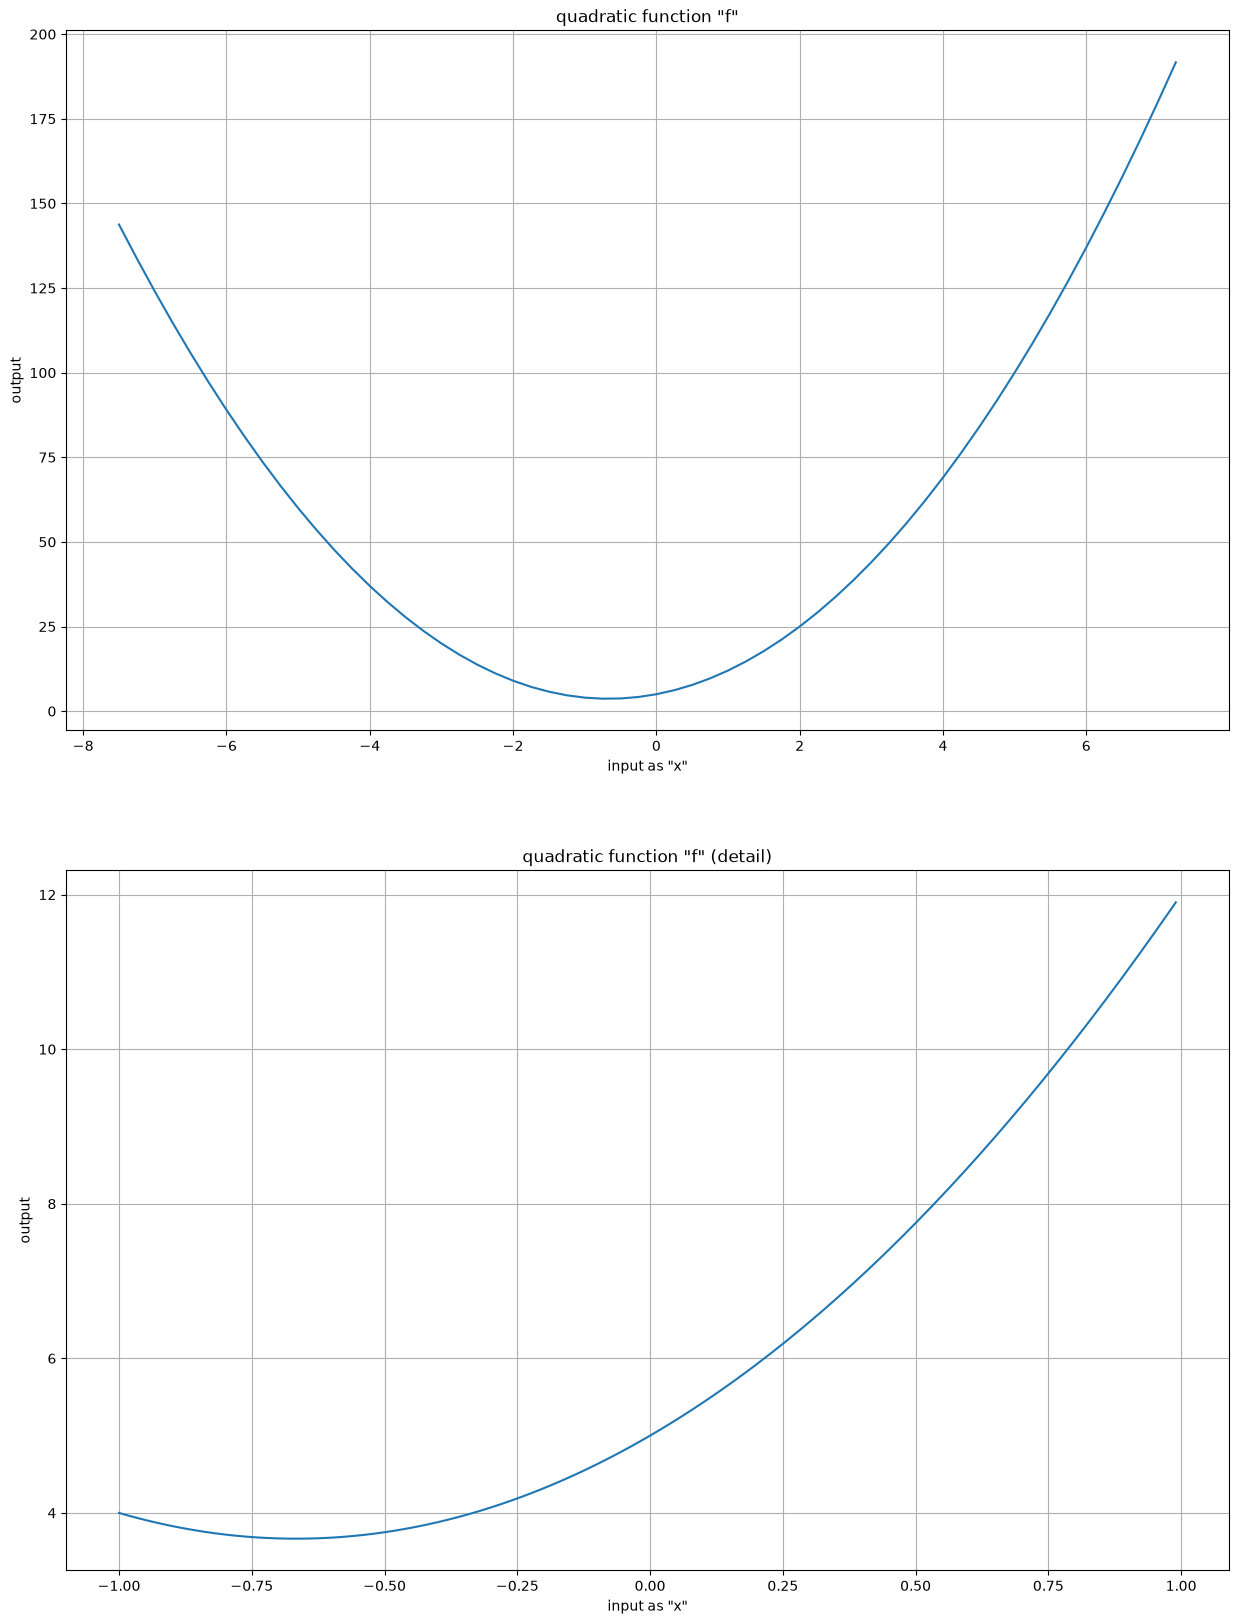

In [20]:
# general graph
xs1 = np.arange(-7.5, 7.5, 0.25)
ys1 = f(xs1)

fig, axs = plt.subplots(2, 1)
fig.set_figwidth(15)
fig.set_figheight(20)

axs[0].plot(xs1, ys1)
axs[0].set(xlabel='input as "x"', ylabel='output',
       title='quadratic function "f"')
axs[0].grid()

# detail graph
xs2 = np.arange(-1, 1, 0.01)
ys2 = f(xs2)

axs[1].plot(xs2, ys2)
axs[1].set(xlabel='input as "x"', ylabel='output',
       title='quadratic function "f" (detail)')
axs[1].grid()

plt.show()

In [21]:
x = 6.0
h = 0.1
print((f(x + h) - f(x))/h) # 40.29999999999973

x = 4.0
h = 0.1
print((f(x + h) - f(x))/h) # 28.29999999999984

40.29999999999973
28.29999999999984


In [22]:
h = 0.1

a = 4.0
def print_info(a, d1, d2, h):
    print('current input', a, 'd1', d1, 'd2', d2)
    print('full difference from d1 to d2', d2 - d1)
    print('normalized slope from d2 to d1', (d2 - d1)/h) # the closer to zero this is the closer we are to the maximum or minimum of this function

d1 = f(a)
a += h
d2 = f(a)
print_info(a, d1, d2, h)
a += h
d3 = f(a)
print_info(a, d2, d3, h)

current input 4.1 d1 69.0 d2 71.82999999999998
full slope from d1 to d2 2.829999999999984
normalized slope from d2 to d1 28.29999999999984
current input 4.199999999999999 d1 71.82999999999998 d2 74.71999999999997
full slope from d1 to d2 2.8899999999999864
normalized slope from d2 to d1 28.899999999999864


the function below can use the slope to move to the minimum or maximum.

In [64]:
def find_valley_1(func, start):
    step_size = 0.001
    count_loops = 0
    while True:
        count_loops += 1

        data1 = func(start)
        data2 = func(start + step_size)
        n = (data2 - data1)/step_size # dividing by our step_size will give us our slope, since this is the distance the two data points on the graph seen from the x-axis. WARNING Do not confuse the term slope with the term angle.
        # print("n", n)
        if abs(n) < 0.1: # we reached the minimum or maximum in the function or slope is now close to zero
            print("amount of loops", count_loops)
            return start

        if n > 0: # if slope is positive subtract
            start -= step_size
        else: # if slope is negative add
            start += step_size



def find_valley_2(func, input):
    step_size = 0.001
    count_loops = 0
    pv_slope = None
    pv_input = None
    while True:
        count_loops += 1

        data1 = func(input)
        data2 = func(input + step_size)
        slope = (data2 - data1)/step_size # dividing by our step_size will give us our slope, since this is the distance the two data points on the graph seen from the x-axis. WARNING Do not confuse the term slope with the term angle.
        # print("slope", slope)

        if pv_slope is None:
            pv_slope = slope
        if pv_input is None:
            pv_input = input

        if slope > 0: # if slope is positive subtract
            if pv_slope < 0:
                print("amount of loops", count_loops)
                return (input + pv_input) / 2
            input -= step_size
        else: # if slope is negative add
            if pv_slope > 0:
                print("amount of loops", count_loops)
                return (input + pv_input) / 2
            input += step_size

        pv_input = input
        pv_slope = slope

def find_valley_3(func, input): # same as find_valley_2 but we make our step size constantly smaller as soon as we reach the switching of the signs from the slope
    pass

def find_valley_4(func, input): # using the bisection method same as binary search thus splits the problem in half.
    pass

a = -6.0
find_valley_1(f, a)
find_valley_2(f, a)

amount of loops 6652
amount of loops 6669


-0.6680000000003385

with the following code we can see how sensitive the output of a formula is to changes from its input parameters.

In [28]:
h = 0.0001

# inputs
a = 2.0
b = -3.0
c = 10.0

# adjusting a
print("== value a ==")
d1 = a*b + c
a += h
d2 = a*b + c
a -= h # undo shifting

print('d1', d1)
print('d2', d2)
print('slope', (d2 - d1)/h)
print()

# adjusting b
print("== value b ==")
d1 = a*b + c
b += h
d2 = a*b + c
b -= h # undo shifting

print('d1', d1)
print('d2', d2)
print('slope', (d2 - d1)/h)
print()

# adjusting c
print("== value c ==")
d1 = a*b + c
c += h
d2 = a*b + c
c -= h # undo shifting

print('d1', d1)
print('d2', d2)
print('slope', (d2 - d1)/h)

== value a ==
d1 4.0
d2 3.999699999999999
slope -3.000000000010772

== value b ==
d1 4.0
d2 4.0002
slope 2.0000000000042206

== value c ==
d1 4.0
d2 4.0001
slope 0.9999999999976694
